# Read regression output into standardized xarray format

In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import os
import re
import glob
import warnings
from tqdm.notebook import tqdm
from dask.diagnostics import ProgressBar

import distributed

from funcs_support import get_filepaths,get_params,utility_save
dir_list = get_params()

In [2]:
#from distributed import Client
#
# Start dask client 
# (playing around with workers, threads for efficiency)
#client = Client(n_workers=6,
#    threads_per_worker=3,
#    processes=True,
#    memory_limit="8GB")
#display(client)

## GDP per capita (BHM15)

In [7]:
def coeffs_gdppc(obstreat='sep',resolution='025deg',timeframe='1980-2010',return_raw = False,joint_=False,get_loos=False):

    # Get relevant filenames
    if get_loos:
        fns = pd.DataFrame({'path':np.sort(glob.glob(dir_list['regs']+'gdppc/loos/reg*.csv'))})
    else:    
        fns = pd.DataFrame({'path':np.sort(glob.glob(dir_list['regs']+'gdppc/reg*.csv'))})
    
    # Extract properties
    fns['datatype'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[1])[0] for fn in fns.path.values]
    fns['resolution'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[3])[0] for fn in fns.path.values]
    fns['proj_base'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[4])[0] for fn in fns.path.values]
    fns['timeframe'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[5])[0] for fn in fns.path.values]
    fns['obstreat'] = ['joint' if re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[-1])[0]=='JOINT' else 'sep' for fn in fns.path.values]

    index_cols = ['proj_base','resolution','timeframe','obstreat','datatype']

    if get_loos:
        fns['loo_id'] = [[n for n in re.split(r'\_',re.split(r'\/',fn)[-1]) if re.search(r'^no.*\.csv$',n)][0][2:-4]
                        for fn in fns.path.values]
        index_cols.append('loo_id')
    
    fns = fns.set_index(index_cols)
    fns = fns.sort_index()
    
    # Subset by desired regression outpus
    fns = fns.iloc[fns.index.get_level_values('obstreat') == obstreat,:]
    if joint_: 
        fns = fns.iloc[fns.index.get_level_values('proj_base') == 'ALLREA',:]
    if len(fns) == 0:
        raise Exception('No output files foud to concatenate')
    
    outputs = {'coeffs':[],
               'vcv':[],
               'coeffs_joint':[],
               'vcv_joint':[]}

    repl_mods = {'ERA5_025':'ERA5',
                 'JRA_3Q':'JRA-3Q'}
    
    for row in fns.iterrows():
        df_tmp = pd.read_csv(row[1]['path'])
    
        # ---- Get column names
        if row[0][0] == 'ALLREA':
            joint_onefile = True
            colnames = [re.sub('temp','tassumpoly_1',re.sub(r'temp\_c\_temp','tassumpoly_2',colname))
                      for colname in df_tmp]
            for obs_mod,rn in repl_mods.items(): 
                colnames = [re.sub(obs_mod,rn,colname) for colname in colnames]
            
            colnames = pd.MultiIndex.from_tuples([(re.split(r'\_',colname)[0],'_'.join(re.split(r'\_',colname)[1:None])) for colname in colnames],
                                             names = ['proj_base','pred'])
            df_tmp.columns = colnames
        else:
            joint_onefile = False
            colnames = ['tassumpoly_1','tassumpoly_2']
            df_tmp.columns = colnames
    
        # ---- Turn into xarray dataset
        if 'coeffs' in row[0]:
            filetyp = 'coeffs'
            if joint_onefile: 
                ds_tmp = df_tmp.melt(value_name='coeffs').set_index(['proj_base','pred']).to_xarray()
            else:
                df_tmp.index = [row[0][0]]
                ds_tmp = df_tmp.to_xarray().rename({'index':'proj_base'}).to_dataarray(dim='pred',name='coeffs')
            
        elif 'vcv' in row[0]:
            filetyp = 'vcv'
            if joint_onefile:
                df_tmp.index = colnames.set_names(['proj_base_1','pred_1'])
                df_tmp.columns = colnames.set_names(['proj_base_2','pred_2'])
                ds_tmp = df_tmp.stack(level=list(range(df_tmp.columns.nlevels))).to_xarray().to_dataset(name='vcv')
            else:
                df_tmp.index = colnames
                ds_tmp = df_tmp.to_xarray().rename({'index':'pred_1'}).to_dataarray(dim='pred_2',name='vcv')
        else:
            print(f'{row[0]} does not contain one of coeffs, vcv, do not know how to deal, skipped.')
    
        # ---- Metadata processing
        # Get names and positions of metadata dimensions
        dim_names = [idx for idx in fns.index.names if idx not in ['datatype']]
        if not (('proj_base' not in ds_tmp.dims) and ('proj_base_1' not in ds_tmp.dims)):
            dim_names = [d for d in dim_names if d != 'proj_base']
        # Add metadata coordinates
        dim_idxs = [fns.index.names.index(idx) for idx in dim_names]
        ds_tmp = ds_tmp.expand_dims({v:[val] for v,val in zip(dim_names,np.array(row[0])[dim_idxs])})
        
        # Add to full list
        if joint_onefile:
            outputs[f'{filetyp}_joint'].append(ds_tmp)
        else:
           outputs[f'{filetyp}'].append(ds_tmp)
    
    # Merge
    for v in outputs:
        if len(outputs[v])>0:
            outputs[v] = xr.merge(outputs[v],join='outer',compat='no_conflicts')
    
    if joint_onefile:
        coeffs_out,vcv_out = outputs['coeffs_joint'],outputs['vcv_joint']
    else:
        coeffs_out,vcv_out = outputs['coeffs'],outputs['vcv']
    
    # Turn ERA5-025 into ERA5
    coeffs_out['proj_base'] = [re.sub(r'^ERA5-025$','ERA5',mod) for mod in coeffs_out.proj_base.values]
    if 'proj_base_1' in vcv_out.sizes:
        for k in [1,2]:
            vcv_out[f'proj_base_{str(k)}'] = [re.sub(r'^ERA5-025$','ERA5',mod) for mod in vcv_out[f'proj_base_{str(k)}'].values]
    else:
        vcv_out['proj_base'] = [re.sub(r'^ERA5-025$','ERA5',mod) for mod in vcv_out.proj_base.values]
    
        
    if not return_raw:
        coeffs_out = coeffs_out.sel(obstreat=obstreat,resolution=resolution,timeframe=timeframe)
        vcv_out= vcv_out.sel(obstreat=obstreat,resolution=resolution,timeframe=timeframe)
    return coeffs_out,vcv_out


In [8]:
coeffs_gdppc(get_loos=True)

(<xarray.Dataset> Size: 17kB
 Dimensions:     (proj_base: 5, pred: 2, loo_id: 195)
 Coordinates:
   * proj_base   (proj_base) <U6 120B 'ERA5' 'GMFD' 'JRA-3Q' 'MERRA2' 'UDel'
   * pred        (pred) object 16B 'tassumpoly_1' 'tassumpoly_2'
   * loo_id      (loo_id) object 2kB 'Afghanistan' 'Albania' ... 'Zimbabwe'
     resolution  <U6 24B '025deg'
     timeframe   <U9 36B '1980-2010'
     obstreat    <U3 12B 'sep'
 Data variables:
     coeffs      (loo_id, pred, proj_base) float64 16kB 0.01565 ... -0.0004771,
 <xarray.Dataset> Size: 33kB
 Dimensions:     (pred_1: 2, pred_2: 2, proj_base: 5, loo_id: 195)
 Coordinates:
   * pred_1      (pred_1) object 16B 'tassumpoly_1' 'tassumpoly_2'
   * pred_2      (pred_2) object 16B 'tassumpoly_1' 'tassumpoly_2'
   * proj_base   (proj_base) <U6 120B 'ERA5' 'GMFD' 'JRA-3Q' 'MERRA2' 'UDel'
   * loo_id      (loo_id) object 2kB 'Afghanistan' 'Albania' ... 'Zimbabwe'
     resolution  <U6 24B '025deg'
     timeframe   <U9 36B '1980-2010'
     obstreat    <

#### old setup

In [151]:
obstreat = 'joint'
obstreat = 'sep'
# Verified that they produce exactly the same coefficients / the same output below. 

def get_coeffs_gdppc(output,obstreat,fns=fns):
    ''' Reading Burke, Hsiang, and Miguel regression output

    Parameters
    --------------
    output : 'coeffs' or 'vcv'

    obstreat : str, by default 'sep'
        'sep': regressions run on each reanalysis separately
        'joint': regressions run jointly interacted with reanalysis product
        

    Returns
    -------------
    coeffs or vcv

    '''
    if output not in ['coeffs','vcv']:
        raise KeyError(f'`output` must be "coeffs" or "vcv", but is "{str(output)}"')
    
    if obstreat not in ['sep','joint']:
        raise KeyError(f'`obstreat` must be "sep" or "joint", but is "{str(obstreat)}"')
    
    dss = []
    if obstreat == 'sep':
        
        for proj_base in [mod for mod in fns.index.unique(level='proj_base') if mod != 'joint']:
            for typ in fns.index.unique(level='timeframe'):
                col_idxs = ['tassumpoly_1','tassumpoly_2']

                if output == 'coeffs':
                    df = pd.read_csv(fns.loc[(proj_base,'Coefficients',typ)].path)
                    df.columns = col_idxs
                    ds_tmp = df.to_xarray().to_dataarray(dim='pred',name='coeffs').isel(index=0,drop=True)
                elif output == 'vcv':
                    df = pd.read_csv(fns.loc[(proj_base,'VCV',typ)].path)
                    df.columns = col_idxs 
                    df.index = pd.Index(col_idxs)
                    ds_tmp = df.to_xarray().to_dataarray(dim='pred_1',name='vcv').rename({'index':'pred_2'})
                
                ds_tmp = ds_tmp.expand_dims({'proj_base':[proj_base],
                                                 'timeframe':[typ]})
                dss.append(ds_tmp)
        dss = xr.combine_by_coords(dss)
    elif obstreat == 'joint':
        # Get order it's encoded in by STATA
        modlist = np.sort([k for k in fns.index.unique(level='proj_base') if k != 'joint'])
    
        for typ in fns.index.unique(level='timeframe'):
            if output == 'coeffs':
                df = pd.read_csv(fns.loc[('joint','Coefficients',typ)].path)
                df = df.iloc[[0],0:(len(modlist)*2)]
                df.columns = pd.MultiIndex.from_product([['tassumpoly_1','tassumpoly_2'],modlist],
                                           names = ['pred','proj_base'])
                ds_tmp = df.melt(value_name='coeffs').set_index(['pred','proj_base']).to_xarray()
                
            elif output == 'vcv':
                df = pd.read_csv(fns.loc[('joint','VCV',typ)].path)
                df = df.iloc[0:(len(modlist)*2),0:(len(modlist)*2)]
                
                df.columns = pd.MultiIndex.from_product([['tassumpoly_1','tassumpoly_2'],modlist],
                                                       names = ['pred_1','proj_base_1'])
                df.index = pd.MultiIndex.from_product([['tassumpoly_1','tassumpoly_2'],modlist],
                                                       names = ['pred_2','proj_base_2'])
                
                ds_tmp = (df.melt(ignore_index=False,value_name='vcv').reset_index().
                          set_index(['pred_1','proj_base_1','pred_2','proj_base_2']).to_xarray())
                
            ds_tmp = ds_tmp.expand_dims({'timeframe':[typ]})
            dss.append(ds_tmp)
        dss = xr.combine_by_coords(dss)#.transpose('pred','proj_base','timeframe')

    return dss

## Mortality (Carleton et al.)

In [4]:
def col_to_index(col,pred_names,obs_names = ['MERRA2','JRA-3Q','ERA5-025','GMFD'],append_cons=True):
    comps = []

    if np.any([re.search(r'^age',k) for k in re.split(r'\_',col)]):
        # Get ageset
        ageset = [k for k in re.split(r'\_',col) if re.search(r'^age',k)][0]
        comps.append(ageset)
        # Remove from col
        col = re.sub(ageset+r'\_','',col)
    
    # Get temperature pred
    pred_name = re.search(r'tavg\_poly\_[0-9]',col).group()
    pred_name_out = [k for k in pred_names if re.search(r'\_'+re.split(r'\_',pred_name)[-1]+r'$',k)][0]
    comps.append(pred_name_out)
    # Remove from col
    col = re.sub(pred_name,'',col)

    if np.any([re.search(re.sub(r'\-','_',mod),col) for mod in obs_names]):
        obs_name = [k.group() for k in [re.search(re.sub(r'\-','_',mod),col) for mod in obs_names] if k is not None][0]
        obs_name_out = re.sub(r'\_','-',obs_name)
        comps.append(obs_name_out)
        # Remove from col
        col = re.sub(obs_name+r'\_','',col)
    
    # Now, any covariates
    if len(col) == 0:
        if append_cons:
            comps.append('1')
    else:
        comps.append(re.split(r'\_c\_',col)[-1])
    
    comps = tuple(comps)
    return comps


In [29]:
get_loos = True
obstreat = 'sep'
spec = 'pooled'
joint_ = False


# Get relevant filenames
fns = pd.DataFrame({'path':np.sort(glob.glob(dir_list['regs']+'mortality/loos/reg*.csv'))})

# Extract properties
fns['datatype'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[1])[0] for fn in fns.path.values]
fns['spec'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[3])[0] for fn in fns.path.values]
fns['resolution'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[4])[0] for fn in fns.path.values]
fns['proj_base'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[5])[0] for fn in fns.path.values]
fns['timeframe'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[6])[0] for fn in fns.path.values]
fns['obstreat'] = [re.split(r'\_',re.search(r'\_JOINT.*[\.\_]',fn).group()[1:-1].lower())[0] if 'JOINT' in fn else 'sep' for fn in fns.path.values]
fns['indflag'] = ['noInd' if 'noIND' in fn else 'wInd' for fn in fns.path.values]

index_cols = ['proj_base','resolution','timeframe','obstreat','spec','indflag','datatype']

if get_loos:
    fns['loo_id'] = [[n for n in re.split(r'\_',re.split(r'\/',fn)[-1]) if re.search(r'^no.*\.csv$',n)][0][2:-4]
                    for fn in fns.path.values]
    index_cols.append('loo_id')

fns = fns.set_index(index_cols)
fns = fns.sort_index()

# Subset by desired regression outpus
fns = fns.iloc[fns.index.get_level_values('spec') == spec,:]
fns = fns.iloc[fns.index.get_level_values('obstreat') == obstreat,:]
if joint_: 
    fns = fns.iloc[fns.index.get_level_values('proj_base') == 'ALLREA',:]
if len(fns) == 0:
    raise Exception('No output files foud to concatenate')

In [53]:
outputs = {'coeffs':[],
               'vcv':[],
               'coeffs_interacted':[],
               'vcv_interacted':[],
               'coeffs_joint':[],
               'vcv_joint':[]}

pred_names = [f'tassumpoly_{str(k)}' for k in np.arange(1,5)]
for row in fns.iterrows():
    df_tmp = pd.read_csv(row[1]['path'])

    # ---- Get column names
    joint_onefile = False
    if row[0][0] == 'ALLREA':
        joint_onefile = True
    
    if np.any(['age' in col for col in df_tmp.columns]):
        interacted = True
        multi_pred_names = pd.MultiIndex.from_tuples([col_to_index(col,pred_names=pred_names) for col in df_tmp.columns],
                              names = ['ageset','pred','covar'])
        df_tmp.columns = multi_pred_names
    else:
        interacted = False
        if joint_onefile:
            colnames = pd.MultiIndex.from_tuples([col_to_index(col,pred_names=pred_names,append_cons=False) for col in df_tmp.columns],
                         names = ['pred','proj_base'])
            df_tmp.columns = colnames
        else:
            df_tmp.columns = pred_names

    # ---- Turn into xarray dataset
    if 'coeffs' in row[0]:
        filetyp = 'coeffs'
        if joint_onefile: 
            ds_tmp = df_tmp.melt(value_name='coeffs').set_index(['proj_base','pred']).to_xarray()
            ds_tmp['pred'] = pred_names
        else:
            # Make obs_mod the index
            df_tmp.index = [row[0][0]]
            if interacted:
                ds_tmp = df_tmp.melt().set_index(['ageset','pred','covar']).sort_index().to_xarray().rename({'value':'coeffs'})
            else:
                ds_tmp = df_tmp.to_xarray().rename({'index':'proj_base'}).to_dataarray(dim='pred',name='coeffs')
            
    elif 'vcv' in row[0]:
        filetyp = 'vcv'
        if joint_onefile:
            df_tmp.index = colnames.set_names(['pred_1','proj_base_1'])
            df_tmp.columns = colnames.set_names(['pred_2','proj_base_2'])
            ds_tmp = df_tmp.stack(level=list(range(df_tmp.columns.nlevels))).to_xarray().to_dataset(name='vcv')
        else:    
            if interacted:
                df_tmp.columns = multi_pred_names.set_names(['ageset_1','pred_1','covar_1'])
                df_tmp.index = multi_pred_names.set_names(['ageset_2','pred_2','covar_2'])
                ds_tmp = df_tmp.stack(level=list(range(df_tmp.columns.nlevels))).to_xarray().to_dataset(name='vcv')
            else:
                df_tmp.index = pred_names
                ds_tmp = df_tmp.to_xarray().rename({'index':'pred_1'}).to_dataarray(dim='pred_2',name='vcv')
    else:
        print(f'Could not find "coeffs" or "vcv" in {str(row[0])}, do not know how to deal, skipped.')
    
    # ---- Metadata processing
    # Get names and positions of metadata dimensions
    dim_names = [idx for idx in fns.index.names if idx not in ['datatype']]
    if not (('proj_base' not in ds_tmp.dims) and ('proj_base_1' not in ds_tmp.dims)):
        dim_names = [d for d in dim_names if d != 'proj_base']
    # Add metadata coordinates
    dim_idxs = [fns.index.names.index(idx) for idx in dim_names]
    ds_tmp = ds_tmp.expand_dims({v:[val] for v,val in zip(dim_names,np.array(row[0])[dim_idxs])})
    
    # Add to full list
    if joint_onefile:
        outputs[f'{filetyp}_joint'].append(ds_tmp)
    else:
        if interacted:
            outputs[f'{filetyp}_interacted'].append(ds_tmp)
        else:
            outputs[f'{filetyp}'].append(ds_tmp)



In [54]:
# Merge
for v in outputs:
    if len(outputs[v])>0:
        outputs[v] = xr.merge(outputs[v],join='outer',compat='no_conflicts')
        if get_loos:
            # Remove India LOOs that are unused 
            outputs[v] = outputs[v].sel(loo_id=[loo_id for loo_id in outputs['coeffs'].loo_id.values if not re.search(r'^india',loo_id)])

In [60]:
def coeffs_mortality(obstreat='sep',resolution='025deg',timeframe='1980-2010',spec='pooled',indflag='noInd',
                     return_raw = False,joint_=False,get_loos = False):



    def col_to_index(col,pred_names,obs_names = ['MERRA2','JRA-3Q','ERA5-025','GMFD'],append_cons=True):
        comps = []
    
        if np.any([re.search(r'^age',k) for k in re.split(r'\_',col)]):
            # Get ageset
            ageset = [k for k in re.split(r'\_',col) if re.search(r'^age',k)][0]
            comps.append(ageset)
            # Remove from col
            col = re.sub(ageset+r'\_','',col)
        
        # Get temperature pred
        pred_name = re.search(r'tavg\_poly\_[0-9]',col).group()
        pred_name_out = [k for k in pred_names if re.search(r'\_'+re.split(r'\_',pred_name)[-1]+r'$',k)][0]
        comps.append(pred_name_out)
        # Remove from col
        col = re.sub(pred_name,'',col)
    
        if np.any([re.search(re.sub(r'\-','_',mod),col) for mod in obs_names]):
            obs_name = [k.group() for k in [re.search(re.sub(r'\-','_',mod),col) for mod in obs_names] if k is not None][0]
            obs_name_out = re.sub(r'\_','-',obs_name)
            comps.append(obs_name_out)
            # Remove from col
            col = re.sub(obs_name+r'\_','',col)
        
        # Now, any covariates
        if len(col) == 0:
            if append_cons:
                comps.append('1')
        else:
            comps.append(re.split(r'\_c\_',col)[-1])
        
        comps = tuple(comps)
        return comps
    
    
    # Get relevant filenames
    if get_loos:
        fns = pd.DataFrame({'path':np.sort(glob.glob(dir_list['regs']+'mortality/loos/reg*.csv'))})
    else:    
        fns = pd.DataFrame({'path':np.sort(glob.glob(dir_list['regs']+'mortality/reg*.csv'))})
    
    # Extract properties
    fns['datatype'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[1])[0] for fn in fns.path.values]
    fns['spec'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[3])[0] for fn in fns.path.values]
    fns['resolution'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[4])[0] for fn in fns.path.values]
    fns['proj_base'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[5])[0] for fn in fns.path.values]
    fns['timeframe'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[6])[0] for fn in fns.path.values]
    fns['obstreat'] = [re.split(r'\_',re.search(r'\_JOINT.*[\.\_]',fn).group()[1:-1].lower())[0] if 'JOINT' in fn else 'sep' for fn in fns.path.values]
    fns['indflag'] = ['noInd' if 'noIND' in fn else 'wInd' for fn in fns.path.values]
    
    index_cols = ['proj_base','resolution','timeframe','obstreat','spec','indflag','datatype']

    if get_loos:
        fns['loo_id'] = [[n for n in re.split(r'\_',re.split(r'\/',fn)[-1]) if re.search(r'^no.*\.csv$',n)][0][2:-4]
                        for fn in fns.path.values]
        index_cols.append('loo_id')
    
    fns = fns.set_index(index_cols)
    fns = fns.sort_index()

    # Subset by desired regression outpus
    fns = fns.iloc[fns.index.get_level_values('spec') == spec,:]
    fns = fns.iloc[fns.index.get_level_values('obstreat') == obstreat,:]
    if joint_: 
        fns = fns.iloc[fns.index.get_level_values('proj_base') == 'ALLREA',:]
    if len(fns) == 0:
        raise Exception('No output files foud to concatenate')
    
    outputs = {'coeffs':[],
               'vcv':[],
               'coeffs_interacted':[],
               'vcv_interacted':[],
               'coeffs_joint':[],
               'vcv_joint':[]}

    pred_names = [f'tassumpoly_{str(k)}' for k in np.arange(1,5)]
    
    for row in fns.iterrows():
        df_tmp = pd.read_csv(row[1]['path'])
    
        # ---- Get column names
        joint_onefile = False
        if row[0][0] == 'ALLREA':
            joint_onefile = True
        
        if np.any(['age' in col for col in df_tmp.columns]):
            interacted = True
            multi_pred_names = pd.MultiIndex.from_tuples([col_to_index(col,pred_names=pred_names) for col in df_tmp.columns],
                                  names = ['ageset','pred','covar'])
            df_tmp.columns = multi_pred_names
        else:
            interacted = False
            if joint_onefile:
                colnames = pd.MultiIndex.from_tuples([col_to_index(col,pred_names=pred_names,append_cons=False) for col in df_tmp.columns],
                             names = ['pred','proj_base'])
                df_tmp.columns = colnames
            else:
                df_tmp.columns = pred_names
    
        # ---- Turn into xarray dataset
        if 'coeffs' in row[0]:
            filetyp = 'coeffs'
            if joint_onefile: 
                ds_tmp = df_tmp.melt(value_name='coeffs').set_index(['proj_base','pred']).to_xarray()
                ds_tmp['pred'] = pred_names
            else:
                # Make obs_mod the index
                df_tmp.index = [row[0][0]]
                if interacted:
                    ds_tmp = df_tmp.melt().set_index(['ageset','pred','covar']).sort_index().to_xarray().rename({'value':'coeffs'})
                else:
                    ds_tmp = df_tmp.to_xarray().rename({'index':'proj_base'}).to_dataarray(dim='pred',name='coeffs')
                
        elif 'vcv' in row[0]:
            filetyp = 'vcv'
            if joint_onefile:
                df_tmp.index = colnames.set_names(['pred_1','proj_base_1'])
                df_tmp.columns = colnames.set_names(['pred_2','proj_base_2'])
                ds_tmp = df_tmp.stack(level=list(range(df_tmp.columns.nlevels))).to_xarray().to_dataset(name='vcv')
            else:    
                if interacted:
                    df_tmp.columns = multi_pred_names.set_names(['ageset_1','pred_1','covar_1'])
                    df_tmp.index = multi_pred_names.set_names(['ageset_2','pred_2','covar_2'])
                    ds_tmp = df_tmp.stack(level=list(range(df_tmp.columns.nlevels))).to_xarray().to_dataset(name='vcv')
                else:
                    df_tmp.index = pred_names
                    ds_tmp = df_tmp.to_xarray().rename({'index':'pred_1'}).to_dataarray(dim='pred_2',name='vcv')
        else:
            print(f'Could not find "coeffs" or "vcv" in {str(row[0])}, do not know how to deal, skipped.')
        
        # ---- Metadata processing
        # Get names and positions of metadata dimensions
        dim_names = [idx for idx in fns.index.names if idx not in ['datatype']]
        if not (('proj_base' not in ds_tmp.dims) and ('proj_base_1' not in ds_tmp.dims)):
            dim_names = [d for d in dim_names if d != 'proj_base']
        # Add metadata coordinates
        dim_idxs = [fns.index.names.index(idx) for idx in dim_names]
        ds_tmp = ds_tmp.expand_dims({v:[val] for v,val in zip(dim_names,np.array(row[0])[dim_idxs])})
        
        # Add to full list
        if joint_onefile:
            outputs[f'{filetyp}_joint'].append(ds_tmp)
        else:
            if interacted:
                outputs[f'{filetyp}_interacted'].append(ds_tmp)
            else:
                outputs[f'{filetyp}'].append(ds_tmp)
    
    # Merge
    for v in outputs:
        if len(outputs[v])>0:
            outputs[v] = xr.merge(outputs[v],join='outer',compat='no_conflicts')
            if get_loos:
                # Remove India LOOs that are unused 
                outputs[v] = outputs[v].sel(loo_id=[loo_id for loo_id in outputs['coeffs'].loo_id.values 
                                                    if not re.search(r'^india',loo_id)])
    
    if joint_onefile:
        coeffs_out,vcv_out = outputs['coeffs_joint'],outputs['vcv_joint']
    elif spec == 'interacted':
        coeffs_out,vcv_out = outputs['coeffs_interacted'],outputs['vcv_interacted']
    else:
        coeffs_out,vcv_out = outputs['coeffs'],outputs['vcv']

    # Turn ERA5-025 into ERA5
    coeffs_out['proj_base'] = [re.sub(r'^ERA5-025$','ERA5',mod) for mod in coeffs_out.proj_base.values]
    if 'proj_base_1' in vcv_out.sizes:
        for k in [1,2]:
            vcv_out[f'proj_base_{str(k)}'] = [re.sub(r'^ERA5-025$','ERA5',mod) for mod in vcv_out[f'proj_base_{str(k)}'].values]
    else:
        vcv_out['proj_base'] = [re.sub(r'^ERA5-025$','ERA5',mod) for mod in vcv_out.proj_base.values]

        
    if not return_raw:
        coeffs_out = coeffs_out.sel(obstreat=obstreat,resolution=resolution,timeframe=timeframe,spec=spec,indflag=indflag)
        vcv_out= vcv_out.sel(obstreat=obstreat,resolution=resolution,timeframe=timeframe,spec=spec,indflag=indflag)
    return coeffs_out,vcv_out
    


In [61]:
coeffs_mortality(get_loos = True)

(<xarray.Dataset> Size: 34kB
 Dimensions:     (proj_base: 4, pred: 4, loo_id: 246)
 Coordinates:
   * proj_base   (proj_base) <U6 96B 'ERA5' 'GMFD' 'JRA-3Q' 'MERRA2'
   * pred        (pred) object 32B 'tassumpoly_1' ... 'tassumpoly_4'
   * loo_id      (loo_id) object 2kB 'AustriaAT1' ... 'United KingdomUKN'
     resolution  <U6 24B '025deg'
     timeframe   <U9 36B '1980-2010'
     obstreat    <U3 12B 'sep'
     spec        <U6 24B 'pooled'
     indflag     <U5 20B 'noInd'
 Data variables:
     coeffs      (loo_id, pred, proj_base) float64 31kB -0.005944 ... 1.27e-06,
 <xarray.Dataset> Size: 128kB
 Dimensions:     (pred_1: 4, pred_2: 4, proj_base: 4, loo_id: 246)
 Coordinates:
   * pred_1      (pred_1) object 32B 'tassumpoly_1' ... 'tassumpoly_4'
   * pred_2      (pred_2) object 32B 'tassumpoly_1' ... 'tassumpoly_4'
   * proj_base   (proj_base) <U6 96B 'ERA5' 'GMFD' 'JRA-3Q' 'MERRA2'
   * loo_id      (loo_id) object 2kB 'AustriaAT1' ... 'United KingdomUKN'
     resolution  <U6 24B '025

#### old setup

In [2]:
fns = pd.DataFrame({'path':np.sort(glob.glob(dir_list['regs']+'mortality/*.csv'))})
fns['proj_base'] = [re.split(r'public\_',re.split(r'\.csv',re.split(r'\/',fn)[-1])[0])[-1] for fn in fns.path.values]
fns['spectype'] = [re.split(r'\_response\_',re.split(r'\/',fn)[-1])[0] for fn in fns.path.values]
fns['datatype'] = ['VCV' if '_VCV_' in fn else 'Coefficients' for fn in fns.path.values]
fns = fns.set_index(['proj_base','datatype','spectype'])

fns = fns.iloc[['nototal' not in fn for fn in fns.path.values],:]

fns = fns.sort_index()

In [174]:
def coeffs_mortality(obstreat,regtyp='pooled'):
    fns = pd.DataFrame({'path':np.sort(glob.glob(dir_list['regs']+'mortality/*.csv'))})
    fns['proj_base'] = [re.split(r'public\_',re.split(r'\.csv',re.split(r'\/',fn)[-1])[0])[-1] for fn in fns.path.values]
    fns['spectype'] = [re.split(r'\_response\_',re.split(r'\/',fn)[-1])[0] for fn in fns.path.values]
    fns['datatype'] = ['VCV' if '_VCV_' in fn else 'Coefficients' for fn in fns.path.values]
    fns = fns.set_index(['proj_base','datatype','spectype'])
    
    fns = fns.iloc[['nototal' not in fn for fn in fns.path.values],:]
    
    fns = fns.sort_index()

    def get_coeffs_mortality(output,obstreat,regtyp='pooled',fns=fns,drop_intersect = True):
        ''' Reading Carleton et al. mortality regression output
    
        Parameters
        --------------
        output : 'coeffs' or 'vcv'
    
        obstreat : str, by default 'sep'
            'sep': regressions run on each reanalysis separately
            'joint': regressions run jointly interacted with reanalysis product
    
        regtyp : str, by default 'pooled'
            'pooled': single regression for the globe
            'Agespec_interaction': regression interacted with GDPpc / long-run climate
    
        drop_intersect : bool, by default True
            If True, then intersect is removed from output
    
        Returns
        -------------
        coeffs or vcv
    
        '''
        if output not in ['coeffs','vcv']:
            raise KeyError(f'`output` must be "coeffs" or "vcv", but is "{str(output)}"')
        
        if obstreat not in ['sep','joint']:
            raise KeyError(f'`obstreat` must be "sep" or "joint", but is "{str(obstreat)}"')
    
        if regtyp not in ['pooled','Agespec_interaction']:
            raise KeyError(f'`regtyp` must be "pooled" or "Agespec_interaction", but is "{str(regtyp)}"')
            
        dss = []
        if obstreat == 'sep':
            for proj_base in [mod for mod in fns.index.unique(level='proj_base') if mod != 'joint']:
                if regtyp == 'pooled':
                    col_idxs = [*[f'tassumpoly_{k}' for k in np.arange(1,5)],'intersect']
    
                    if output == 'coeffs':
                        df = pd.read_csv(fns.loc[(proj_base,'Coefficients',regtyp)].path)
                        df.columns = col_idxs
                        ds_tmp = df.to_xarray().to_dataarray(dim='pred',name='coeffs').isel(index=0,drop=True)
                        ds_tmp = ds_tmp.expand_dims({'covar':['1'],'ageset':['total']})
    
                    elif output == 'vcv':
                        df = pd.read_csv(fns.loc[(proj_base,'VCV',regtyp)].path)
                        df.columns = col_idxs
                        df.index = col_idxs
                        ds_tmp = df.to_xarray().to_dataarray(dim='pred_1',name='vcv').rename({'index':'pred_2'})
    
                    ds_tmp = ds_tmp.expand_dims({'proj_base':[proj_base],
                                                  'spectype':[regtyp]}) 
                    ds_tmp = ds_tmp.to_dataset()
                
                    dss.append(ds_tmp)
                elif regtyp == 'Agespec_interaction':
                    # Set columns from fully interacted model reg call
                    #* Fully interacted model
                    # reghdfe deathrate_w99 c.tavg_poly_1#i.agegroup_ c.tavg_poly_2#i.agegroup_ ///
                    #				c.tavg_poly_3#i.agegroup_ c.tavg_poly_4#i.agegroup_ ///
                    #				c.tavg_poly_1#c.loggdppc_adm1_avg#i.agegroup_ c.tavg_poly_2#c.loggdppc_adm1_avg#i.agegroup_ ///
                    #				c.tavg_poly_3#c.loggdppc_adm1_avg#i.agegroup_ c.tavg_poly_4#c.loggdppc_adm1_avg#i.agegroup_ ///
                    #				c.tavg_poly_1#c.lr_tavg_adm1_avg#i.agegroup_ c.tavg_poly_2#c.lr_tavg_adm1_avg#i.agegroup_ ///
                    #				c.tavg_poly_3#c.lr_tavg_adm1_avg#i.agegroup_ c.tavg_poly_4#c.lr_tavg_adm1_avg#i.agegroup_ 
                    # In this order: "0-4"' `"5-64"' `"65+"' `"total"'
                    levels = ['young','middle','old','total']
                    tpreds = [f'tassumpoly_{k}' for k in np.arange(1,5)]
                    covars = ['1','tasmean','gdppc']
                    
                    tpreds_full = list(np.repeat(tpreds,len(levels)))*len(covars)
                    levels_full = (levels*len(tpreds))*len(covars)
                    covars_full = np.repeat(covars,len(tpreds)*len(levels))
                    
                    col_idxs = pd.DataFrame({'pred':tpreds_full,
                                              'covar':covars_full,
                                              'ageset':levels_full})
                    # Really should just instead repeat it x times across agesets
                    col_idxs = pd.concat([col_idxs,
                                          pd.DataFrame({'pred':['intersect'],
                                                       'covar':['1'],
                                                       'ageset':['intersect']})])
                    col_idxs = pd.MultiIndex.from_frame(col_idxs)
    
                    # Load coefficients
                    if output == 'coeffs':
                        df = pd.read_csv(fns.loc[(proj_base,'Coefficients',regtyp)].path)
                        df.columns = pd.MultiIndex.from_frame(col_idxs)
                        
                        # Prepare for xarray
                        df['proj_base'] = proj_base
                        df['spectype'] = regtyp
                        df = df.set_index(['proj_base','spectype'])
                        df = df.melt(ignore_index=False,value_name='coeffs').reset_index().set_index(['proj_base','spectype','pred','covar','ageset'])
                        
                        # To xarray
                        ds_tmp = df.to_xarray()
                    elif output == 'vcv':
                        df = pd.read_csv(fns.loc[('ERA5-025','VCV','Agespec_interaction')].path)
                        df.columns = col_idxs.set_names(['pred_1','covar_1','ageset_1'])
                        df.index = col_idxs.set_names(['pred_2','covar_2','ageset_2'])
    
                        ds_tmp = (df.melt(ignore_index=False,value_name='vcv').reset_index().
                                        set_index(['pred_1','covar_1','ageset_1','pred_2','covar_2','ageset_2']).to_xarray())
                        
                        ds_tmp = ds_tmp.expand_dims({'proj_base':[proj_base],
                                                                 'spectype':[regtyp]}) 
    
                    dss.append(ds_tmp)
        elif obstreat == 'joint':
            if regtyp == 'pooled':
                # Get order it's encoded in by STATA
                modlist = np.sort([k for k in fns.index.unique(level='proj_base') if k != 'joint'])
                
                col_idxs = pd.MultiIndex.from_product([[f'tassumpoly_{k}' for k in np.arange(1,5)],modlist],
                                                       names = ['pred','proj_base'])
                col_idxs = col_idxs.append(pd.MultiIndex.from_tuples([('intersect','intersect')],names=['pred','proj_base']))
                
                if output == 'coeffs':
                    df = pd.read_csv(fns.loc[('joint','Coefficients',regtyp)].path)
                    df.columns = col_idxs
                    
                    ds_tmp = df.melt(value_name='coeffs').set_index(['pred','proj_base']).to_xarray()
                    ds_tmp = ds_tmp.expand_dims({'covar':['1'],'ageset':['total']})
                    
    
                elif output == 'vcv':
                    df = pd.read_csv(fns.loc[('joint','VCV',regtyp)].path)
                    
                    df.columns = col_idxs.set_names(['pred_1','proj_base_1'])
                    df.index = col_idxs.set_names(['pred_2','proj_base_2'])
            
                    ds_tmp = (df.melt(ignore_index=False,value_name='vcv').reset_index().
                                  set_index(['pred_1','proj_base_1','pred_2','proj_base_2']).to_xarray())
                ds_tmp = ds_tmp.expand_dims({'spectype':[regtyp]}) 
                dss.append(ds_tmp)
            
            elif regtyp == 'Agespec_interaction':
                raise KeyError('joint-reanalysis fully interacted model not run yet')
                        
        dss = xr.merge(dss,join='outer',compat='no_conflicts')
    
        if drop_intersect:
            if output == 'coeffs':
                for dim in ['pred','ageset','proj_base']:
                    dss = dss.sel({dim:[d for d in dss[dim].values if d != 'intersect']})
            elif output == 'vcv':
                dss = dss.sel({f'pred_{k}':[p for p in dss[f'pred_{k}'].values if p != 'intersect'] for k in [1,2]})
                if 'proj_base_1' in dss.sizes:
                    dss = dss.sel({f'proj_base_{k}':[p for p in dss[f'proj_base_{k}'].values if p != 'intersect'] for k in [1,2]})
    
        # Make singleton dimensions empty coordinates instead
        for dim in [d for d in dss.sizes if d not in ['proj_base','pred']]:
            if dss.sizes[dim] == 1:
                dss = dss.isel({dim:0})
        
        return dss

In [173]:
coeffs,vcv = get_coeffs_mortality('coeffs','joint'),get_coeffs_mortality('vcv','joint')
coeffs,vcv

(<xarray.Dataset> Size: 240B
 Dimensions:    (pred: 4, proj_base: 4)
 Coordinates:
   * pred       (pred) object 32B 'tassumpoly_1' ... 'tassumpoly_4'
   * proj_base  (proj_base) object 32B 'ERA5-025' 'GMFD' 'JRA-3Q' 'MERRA2'
     spectype   <U6 24B 'pooled'
     covar      <U1 4B '1'
     ageset     <U5 20B 'total'
 Data variables:
     coeffs     (pred, proj_base) float64 128B -0.00962 -0.00847 ... -7.47e-07,
 <xarray.Dataset> Size: 2kB
 Dimensions:      (pred_1: 4, proj_base_1: 4, pred_2: 4, proj_base_2: 4)
 Coordinates:
   * pred_1       (pred_1) object 32B 'tassumpoly_1' ... 'tassumpoly_4'
   * proj_base_1  (proj_base_1) object 32B 'ERA5-025' 'GMFD' 'JRA-3Q' 'MERRA2'
   * pred_2       (pred_2) object 32B 'tassumpoly_1' ... 'tassumpoly_4'
   * proj_base_2  (proj_base_2) object 32B 'ERA5-025' 'GMFD' 'JRA-3Q' 'MERRA2'
     spectype     <U6 24B 'pooled'
 Data variables:
     vcv          (pred_1, proj_base_1, pred_2, proj_base_2) float64 2kB 6.4e-...)

In [64]:
proc_params = {'spectype':'pooled'}
coeff_draws = xr.concat([xr.DataArray(rng.multivariate_normal(coeffs.sel({'proj_base':pb,**proc_params}).coeffs,
                        vcv.sel({'proj_base':pb,**proc_params}).vcv,
                        size=ndraws),
                       dims=['ndraws','pred'],
                       coords = {'pred':coeffs.pred.values})
           for pb in coeffs.proj_base.values],
          dim = pd.Index(coeffs.proj_base.values,name='proj_base'))

In [88]:
Ts = xr.concat([xr.DataArray(np.arange(-10,41),coords = {'t':('t',np.arange(-10,41))},
             dims = ('t'),name='tcoeff')**k
           for k in np.arange(1,5)],
          dim = pd.Index([f'tassumpoly_{k}' for k in np.arange(1,5)],
                         name='pred'),
               )
resps = (coeff_draws*Ts).sum('pred')

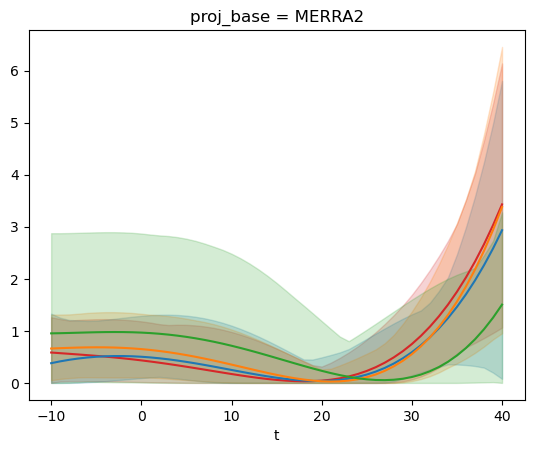

In [91]:
from matplotlib import pyplot as plt
colors = {'ERA5-025':'tab:red','JRA-3Q':'tab:orange','MERRA2':'tab:green','GMFD':'tab:blue'}
ax = plt.subplot()

for pb in resps.proj_base.values:
    plot_data = resps.sel(proj_base=pb)
    plot_data = (plot_data - plot_data.min('t'))

    ax.fill_between(plot_data.t.values,
                    plot_data.min('ndraws').values,
                    plot_data.max('ndraws').values,
                    color=colors[pb],
                    alpha=0.2)
    plot_data.mean('ndraws').plot(color=colors[pb])
    
    

## Payroll (Behrer et al.)

In [23]:
fns = pd.DataFrame({'path':np.sort(glob.glob(dir_list['regs']+'payroll/*.csv'))})


In [24]:
fns.path.values[0]

'/glade/derecho/scratch/schwarzwald/impact_uncertainty/reg_outputs/payroll/regoutputs_coeffs_payroll_025deg_pop_ALLREA_1986-2011_JOINT.csv'

In [62]:

def coeffs_payroll(obstreat='sep',resolution='025deg',timeframe='1986-2008',weighting='pop',
                   joint_ = False,
                     return_raw = False,get_loos=False):
    
    # ---- Get filepaths of regression output csvs
    # Get relevant filenames
    if get_loos:
        fns = pd.DataFrame({'path':np.sort(glob.glob(dir_list['regs']+'payroll/loos/reg*.csv'))})
    else:    
        fns = pd.DataFrame({'path':np.sort(glob.glob(dir_list['regs']+'payroll/reg*.csv'))})
    
    fns['datatype'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[1])[0] for fn in [re.sub(r'pooled\_','',fn) for fn in [re.sub(r'pooled\_','',fn) for fn in fns.path.values]]]
    fns['weighting'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[4])[0] for fn in [re.sub(r'pooled\_','',fn) for fn in [re.sub(r'pooled\_','',fn) for fn in fns.path.values]]]
    fns['resolution'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[3])[0] for fn in [re.sub(r'pooled\_','',fn) for fn in [re.sub(r'pooled\_','',fn) for fn in fns.path.values]]]
    fns['proj_base'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[5])[0] for fn in [re.sub(r'pooled\_','',fn) for fn in [re.sub(r'pooled\_','',fn) for fn in fns.path.values]]]
    fns['timeframe'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[6])[0] for fn in [re.sub(r'pooled\_','',fn) for fn in [re.sub(r'pooled\_','',fn) for fn in fns.path.values]]]
    fns['obstreat'] = [re.split(r'\_',re.search(r'\_JOINT.*[\.\_]',fn).group()[1:-1].lower())[0] if 'JOINT' in fn else 'sep' for fn in [re.sub(r'pooled\_','',fn) for fn in fns.path.values]]
    # NB: the replacement of "pooled" is due to an issue with the filenames in the VCVs, which incorrectly have "pooled" in them as a consequence of a copy-paste issue. 
    
    index_cols = ['proj_base','resolution','timeframe','obstreat','weighting','datatype']

    if get_loos:
        fns['loo_id'] = [[n for n in re.split(r'\_',re.split(r'\/',fn)[-1]) if re.search(r'^no.*\.csv$',n)][0][2:-4]
                        for fn in [re.sub(r'pooled\_','',fn) for fn in fns.path.values]]
        index_cols.append('loo_id')
        
    fns = fns.set_index(index_cols)
    fns = fns.sort_index()
    
    # Subset by desired regression outpus
    fns = fns.iloc[fns.index.get_level_values('obstreat') == obstreat,:]
    if joint_: 
        fns = fns.iloc[fns.index.get_level_values('proj_base') == 'ALLREA',:]
    if len(fns) == 0:
        raise Exception('No output files foud to concatenate')
    
    
    outputs = {'coeffs':[],
               'vcv':[],
               'coeffs_joint':[],
               'vcv_joint':[]}
    
    repl_mods = {'ERA5_025':'ERA5',
                     'JRA_3Q':'JRA-3Q'}
    
    # ---- Process each file in directory that fits desired qualities
    for row in fns.iterrows():#tqdm(fns.iterrows(),total=len(fns)):#fns.iterrows():
        df_tmp = pd.read_csv(row[1]['path'])
    
        # ---- Get column names
        if row[0][0] == 'ALLREA':
            joint_onefile = True
            colnames = [col for col in df_tmp]
            for obs_mod,rn in repl_mods.items(): 
                colnames = [re.sub(obs_mod,rn,colname) for colname in colnames]
            
            colnames = pd.MultiIndex.from_tuples([(re.split(r'\_',colname)[0],'_'.join(re.split(r'\_',colname)[1:None])) for colname in colnames],
                                             names = ['proj_base','pred'])
            df_tmp.columns = colnames
        else:
            joint_onefile = False
            #colnames = ['tassumpoly_1','tassumpoly_2']
            #df_tmp.columns = colnames
    
        # ---- Turn into xarray dataset
        if 'coeffs' in row[0]:
            filetyp = 'coeffs'
            if joint_onefile:
                ds_tmp = df_tmp.melt(value_name='coeffs').set_index(['proj_base','pred']).to_xarray()
            else:
                ds_tmp = df_tmp.melt(value_name='coeffs').rename({'variable':'pred'},axis=1).set_index(['pred']).to_xarray()
        elif 'vcv' in row[0]:
            filetyp = 'vcv'
            if joint_onefile:
                df_tmp.index = colnames.set_names(['proj_base_1','pred_1'])
                df_tmp.columns = colnames.set_names(['proj_base_2','pred_2'])
                ds_tmp = df_tmp.stack(level=list(range(df_tmp.columns.nlevels))).to_xarray().to_dataset(name='vcv')
            else:
                df_tmp.index = df_tmp.columns.copy()
                df_tmp.index.name = 'pred_2'
                df_tmp.columns.name = 'pred_1'
                
                ds_tmp = df_tmp.melt(ignore_index=False).reset_index().set_index(['pred_1','pred_2']).to_xarray().rename({'value':'vcv'})
        else:
            print(f'{row[0][-1]} is not one of coeffs, vcv, do not know how to deal, skipped.')
    
        # Get just the value for days > 90
        if 'pred_1' in ds_tmp.dims:
            ds_tmp = ds_tmp.sel(pred_1 = ['days90plus'],
                                pred_2 = ['days90plus'])
        else:
            ds_tmp = ds_tmp.sel(pred = ['days90plus'])
    
        # ---- Metadata processing
        # Get names and positions of metadata dimensions
        dim_names = [idx for idx in fns.index.names if idx not in ['datatype']]
        if not (('proj_base' not in ds_tmp.dims) and ('proj_base_1' not in ds_tmp.dims)):
            dim_names = [d for d in dim_names if d != 'proj_base']
        # Add metadata coordinates
        dim_idxs = [fns.index.names.index(idx) for idx in dim_names]
        ds_tmp = ds_tmp.expand_dims({v:[val] for v,val in zip(dim_names,np.array(row[0])[dim_idxs])})

        # Add to full list
        if joint_onefile:
            outputs[f'{filetyp}_joint'].append(ds_tmp)
        else:
           outputs[f'{filetyp}'].append(ds_tmp)
            
    # Merge
    for v in outputs:
        if len(outputs[v])>0:
            outputs[v] = xr.merge(outputs[v],join='outer',compat='no_conflicts')
    
    if joint_onefile:
        coeffs_out,vcv_out = outputs['coeffs_joint'],outputs['vcv_joint']
    else:
        coeffs_out,vcv_out = outputs['coeffs'],outputs['vcv']
    
    # Turn ERA5-025 into ERA5
    coeffs_out['proj_base'] = [re.sub(r'^ERA5-025$','ERA5',mod) for mod in coeffs_out.proj_base.values]
    if 'proj_base_1' in vcv_out.sizes:
        for k in [1,2]:
            vcv_out[f'proj_base_{str(k)}'] = [re.sub(r'^ERA5-025$','ERA5',mod) for mod in vcv_out[f'proj_base_{str(k)}'].values]
    else:
        vcv_out['proj_base'] = [re.sub(r'^ERA5-025$','ERA5',mod) for mod in vcv_out.proj_base.values]
    
        
    if not return_raw:
        coeffs_out = coeffs_out.sel(obstreat=obstreat,resolution=resolution,timeframe=timeframe,weighting=weighting)
        vcv_out= vcv_out.sel(obstreat=obstreat,resolution=resolution,timeframe=timeframe,weighting=weighting)
    return coeffs_out,vcv_out


In [63]:
coeffs = coeffs_payroll(get_loos=True,timeframe='ALLYEARS')

  0%|          | 0/30950 [00:00<?, ?it/s]

In [322]:
df_tmp = pd.read_csv(fns.iloc[0].path)
joint_onefile = True


In [275]:
def coeffs_payroll(obstreat='sep',resolution='025deg',timeframe='1980-2011',weighting='pop',
                   joint_type = 'sep',
                     return_raw = False):
    repl_mods = {'ERA5_025':'ERA5',
                 'JRA_3Q':'JRA-3Q'}
    
    fns = pd.DataFrame({'path':np.sort(glob.glob(dir_list['regs']+'payroll/*.csv'))})
    
    fns['datatype'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[1])[0] for fn in [re.sub(r'pooled\_','',fn) for fn in fns.path.values]]
    fns['weighting'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[4])[0] for fn in [re.sub(r'pooled\_','',fn) for fn in fns.path.values]]
    fns['resolution'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[3])[0] for fn in [re.sub(r'pooled\_','',fn) for fn in fns.path.values]]
    fns['proj_base'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[5])[0] for fn in [re.sub(r'pooled\_','',fn) for fn in fns.path.values]]
    fns['timeframe'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[6])[0] for fn in [re.sub(r'pooled\_','',fn) for fn in fns.path.values]]
    fns['obstreat'] = [re.split(r'\_',re.search(r'\_JOINT.*[\.\_]',fn).group()[1:-1].lower())[0] if 'JOINT' in fn else 'sep' for fn in [re.sub(r'pooled\_','',fn) for fn in fns.path.values]]
    # NB: the replacement of "pooled" is due to an issue with the filenames in the VCVs, which incorrectly have "pooled" in them as a consequence of a copy-paste issue. 
    
    fns = fns.set_index(['proj_base','resolution','timeframe','obstreat','weighting','datatype'])
    fns = fns.sort_index()
    
    coeffs = []
    coeffs_all = []
    vcvs = []
    vcvs_all = []
    
    for row in fns.iterrows():
        df_tmp = pd.read_csv(row[1]['path'])
        if row[0][-1] == 'coeffs':
            if row[0][0] == 'ALLREA':
                for obs_mod,rn in repl_mods.items():
                    df_tmp.columns = [re.sub(obs_mod,rn,colname) for colname in df_tmp]
                
                df_tmp.columns = pd.MultiIndex.from_tuples([(re.split(r'\_',colname)[0],'_'.join(re.split(r'\_',colname)[1:None])) for colname in df_tmp.columns],
                                         names = ['proj_base','pred'])
                
                ds_tmp = df_tmp.melt(value_name='coeffs').set_index(['proj_base','pred']).to_xarray()
                
                # Get names and positions of metadata dimensions
                dim_names = [idx for idx in fns.index.names if idx not in ['proj_base','datatype']]
                dim_idxs = [fns.index.names.index(idx) for idx in dim_names]
            else:
                ds_tmp = df_tmp.melt(value_name='coeffs').rename({'variable':'pred'},axis=1).set_index(['pred']).to_xarray()
                
                # Get names and positions of metadata dimensions
                dim_names = [idx for idx in fns.index.names if idx not in ['datatype']]
                dim_idxs = [fns.index.names.index(idx) for idx in dim_names]
            
            
            # Put in format that can be propagated easily, 
            # across all temperature bins above 90 degrees            
            #bin_names = [f'tasmaxbinF_{str(bin)}' for bin in np.arange(92.5,127.6,5)]
            
            ds_tmp = ds_tmp.sel(pred = ['days90plus'])#.expand_dims({'pred':bin_names})
            
            ds_tmp = ds_tmp.expand_dims({v:[val] for v,val in zip(dim_names,
                                          np.array(row[0])[dim_idxs])})
    
            if row[0][0] == 'ALLREA':
                coeffs_all.append(ds_tmp)
            else:
                coeffs.append(ds_tmp)
        elif row[0][-1] == 'vcv':
            if row[0][0] == 'ALLREA':
    
                for obs_mod,rn in repl_mods.items():
                    df_tmp.columns = [re.sub(obs_mod,rn,colname) for colname in df_tmp]
                
                colnames = df_tmp.columns.copy()
                df_tmp.columns = pd.MultiIndex.from_tuples([(re.split(r'\_',colname)[0],'_'.join(re.split(r'\_',colname)[1:None])) for colname in colnames],
                                         names = ['proj_base_1','pred_1'])
                df_tmp.index = pd.MultiIndex.from_tuples([(re.split(r'\_',colname)[0],'_'.join(re.split(r'\_',colname)[1:None])) for colname in colnames],
                                         names = ['proj_base_2','pred_2'])
                
                ds_tmp = (df_tmp.melt(ignore_index=False).rename({'value':'vcv'},axis=1).reset_index().
                 set_index(['proj_base_1','pred_1','proj_base_2','pred_2']).sort_index()).to_xarray()
                
    
                # Get names and positions of metadata dimensions
                dim_names = [idx for idx in fns.index.names if idx not in ['proj_base','datatype']]
                dim_idxs = [fns.index.names.index(idx) for idx in dim_names]
            
            else:
                df_tmp.index = df_tmp.columns.copy()
                df_tmp.index.name = 'pred_2'
                df_tmp.columns.name = 'pred_1'
                
                ds_tmp = df_tmp.melt(ignore_index=False).reset_index().set_index(['pred_1','pred_2']).to_xarray().rename({'value':'vcv'})
    
                # Get names and positions of metadata dimensions
                dim_names = [idx for idx in fns.index.names if idx not in ['datatype']]
                dim_idxs = [fns.index.names.index(idx) for idx in dim_names]
    
            # Get just hte value for days > 90
            ds_tmp = ds_tmp.sel(pred_1 = ['days90plus'],
                                    pred_2 = ['days90plus'])
            
            # Add metadata dimensions
            ds_tmp = ds_tmp.expand_dims({v:[val] for v,val in zip(dim_names,
                                      np.array(row[0])[dim_idxs])})
            
            if row[0][0] == 'ALLREA':
                vcvs_all.append(ds_tmp)
            else:
                vcvs.append(ds_tmp)
        
    coeffs = xr.merge(coeffs,join='outer',compat='no_conflicts')
    coeffs_all = xr.merge(coeffs_all,join='outer',compat='no_conflicts')
    vcvs = xr.merge(vcvs,join='outer',compat='no_conflicts')
    vcvs_all = xr.merge(vcvs_all,join='outer',compat='no_conflicts')
    

    if joint_type == 'sep':
        if return_raw:
            return coeffs,vcvs
        else:
            coeffs = coeffs.sel(obstreat=obstreat,resolution=resolution,timeframe=timeframe,weighting=weighting)
            vcvs = vcvs.sel(obstreat=obstreat,resolution=resolution,timeframe=timeframe,weighting=weighting)
            return coeffs,vcvs
    else:
        if return_raw:
            return coeffs_all,vcvs_all
        else:
            coeffs_all = coeffs_all.sel(obstreat=obstreat,resolution=resolution,timeframe=timeframe,weighting=weighting)
            vcvs_all = vcvs_all.sel(obstreat=obstreat,resolution=resolution,timeframe=timeframe,weighting=weighting)
            return coeffs,vcvs



In [277]:
coeffs_all.pred

<xarray.DataArray 'pred' (pred: 1)> Size: 8B
array(['days90plus'], dtype=object)
Coordinates:
  * pred     (pred) object 8B 'days90plus'

#### Old code

In [2]:
fns = pd.DataFrame({'path':np.sort(glob.glob(dir_list['regs']+r'payroll/regresults*tasmax*.csv'))})
fns = fns.iloc[[not re.search(r'\_os\_',fn) for fn in fns['path'].values]]
fns['proj_base'] = [re.split(r'\_',re.split(r'\/',fn)[-1])[3] for fn in fns['path'].values]
fns['wghttyp'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[4])[0] for fn in fns['path'].values]
fns = fns.set_index(['proj_base','wghttyp'])

obstreat = 'sep'
wghttyp = 'pop'
output = 'coeffs'

In [53]:
def coeffs_payroll(obstreat,wghttyp='pop'):
    fns = pd.DataFrame({'path':np.sort(glob.glob(dir_list['regs']+r'payroll/regresults*tasmax*.csv'))})
    fns = fns.iloc[[not re.search(r'\_os\_',fn) for fn in fns['path'].values]]
    fns['proj_base'] = [re.split(r'\_',re.split(r'\/',fn)[-1])[3] for fn in fns['path'].values]
    fns['wghttyp'] = [re.split(r'\.csv',re.split(r'\_',re.split(r'\/',fn)[-1])[4])[0] for fn in fns['path'].values]
    fns = fns.set_index(['proj_base','wghttyp'])

    def get_coeffs_payroll(output,obstreat,wghttyp=wghttyp,fns=fns):
        dss = []
        
        if obstreat == 'sep':
            for proj_base in [mod for mod in fns.index.unique(level='proj_base') if mod != 'joint']:
        
                df = pd.read_csv(fns.loc[(proj_base,wghttyp),'path'],sep='\t',skiprows=1)
                df.columns = ['param','vals']
                df['varname'] = ['b','se','p']*int(len(df)/3)
                df['param'] = np.repeat(list(df.loc[np.arange(0,len(df),3),'param'].values),3)
                df = df.pivot(index='param',values = 'vals',columns ='varname')
        
                df = df.loc[['days90plus']]
        
                # Put in format that can be propagated easily, 
                # across all temperature bins above 90 degrees
                bin_names = [f'tasmaxbinF_{str(bin)}' for bin in np.arange(92.5,127.6,5)]
                df = pd.concat([df.rename({'days90plus':bn}) for bn in bin_names])
        
                # To xarray
                ds_tmp = df[['b','se']].to_xarray()
                ds_tmp = ds_tmp.rename({'b':'coeffs','se':'vcv','param':'pred'})
        
                if output == 'coeffs':
                    ds_tmp = ds_tmp[['coeffs']]
                elif output == 'vcv':
                    # Since just a single predictor (days > 90) that we're 
                    # awkwardly expanding out across bins to make the syntax
                    # clearer in `3_project_impacts`, make the VCV a 
                    # corresponding diagonal matrix
                    ds_tmp = xr.DataArray(np.diag(ds_tmp['vcv'].values),
                     dims = ['pred_1','pred_2'],
                     coords = {'pred_1':(('pred_1'),ds_tmp.pred.values),
                               'pred_2':(('pred_2'),ds_tmp.pred.values)}).to_dataset(name='vcv')
        
                 # Add proj_base dimension
                ds_tmp = ds_tmp.expand_dims({'proj_base':[proj_base]})
        
                # Add to full dataset
                dss.append(ds_tmp)
        
            # Make into single ds
            dss = xr.merge(dss,join='outer',compat='no_conflicts')
        
            return dss

    coeffs,vcv = get_coeffs_payroll('coeffs',obstreat,wghttyp),get_coeffs_payroll('vcv',obstreat,wghttyp)

    # Turn ERA5-025 into ERA5
    coeffs['proj_base'] = [re.sub(r'^ERA5-025$','ERA5',mod) for mod in coeffs.proj_base.values]
    if 'proj_base_1' in vcv.sizes:
        for k in [1,2]:
            vcv[f'proj_base_{str(k)}'] = [re.sub(r'^ERA5-025$','ERA5',mod) for mod in vcv[f'proj_base_{str(k)}'].values]
    else:
        vcv['proj_base'] = [re.sub(r'^ERA5-025$','ERA5',mod) for mod in vcv.proj_base.values]

    return coeffs,vcv

In [54]:
coeffs_payroll('sep')

(<xarray.Dataset> Size: 416B
 Dimensions:    (pred: 8, proj_base: 4)
 Coordinates:
   * pred       (pred) object 64B 'tasmaxbinF_92.5' ... 'tasmaxbinF_127.5'
   * proj_base  (proj_base) <U6 96B 'ERA5' 'JRA-3Q' 'MERRA2' 'PRISM'
 Data variables:
     coeffs     (proj_base, pred) float64 256B -0.0003274 ... -0.0003483,
 <xarray.Dataset> Size: 2kB
 Dimensions:    (pred_1: 8, pred_2: 8, proj_base: 4)
 Coordinates:
   * pred_1     (pred_1) object 64B 'tasmaxbinF_92.5' ... 'tasmaxbinF_127.5'
   * pred_2     (pred_2) object 64B 'tasmaxbinF_92.5' ... 'tasmaxbinF_127.5'
   * proj_base  (proj_base) <U6 96B 'ERA5' 'JRA-3Q' 'MERRA2' 'PRISM'
 Data variables:
     vcv        (proj_base, pred_1, pred_2) float64 2kB 0.0001195 ... 0.0001191)

In [41]:
ds_tmp

<xarray.Dataset> Size: 192B
Dimensions:  (pred: 8)
Coordinates:
  * pred     (pred) object 64B 'tasmaxbinF_92.5' ... 'tasmaxbinF_127.5'
Data variables:
    coeffs   (pred) float64 64B -0.0003274 -0.0003274 ... -0.0003274 -0.0003274
    vcv      (pred) float64 64B 0.0001195 0.0001195 ... 0.0001195 0.0001195

In [32]:
ds_tmp

<xarray.Dataset> Size: 192B
Dimensions:  (param: 8)
Coordinates:
  * param    (param) object 64B 'tasmaxbinF_92.5' ... 'tasmaxbinF_127.5'
Data variables:
    b        (param) float64 64B -0.0003274 -0.0003274 ... -0.0003274 -0.0003274
    se       (param) float64 64B 0.0001195 0.0001195 ... 0.0001195 0.0001195

In [33]:
ds_tmp = ds_tmp.rename({'b':'coeffs','param':'pred','se':'vcv'})

In [173]:
coeffs,vcv = get_coeffs_mortality('coeffs','joint'),get_coeffs_mortality('vcv','joint')
coeffs,vcv

(<xarray.Dataset> Size: 240B
 Dimensions:    (pred: 4, proj_base: 4)
 Coordinates:
   * pred       (pred) object 32B 'tassumpoly_1' ... 'tassumpoly_4'
   * proj_base  (proj_base) object 32B 'ERA5-025' 'GMFD' 'JRA-3Q' 'MERRA2'
     spectype   <U6 24B 'pooled'
     covar      <U1 4B '1'
     ageset     <U5 20B 'total'
 Data variables:
     coeffs     (pred, proj_base) float64 128B -0.00962 -0.00847 ... -7.47e-07,
 <xarray.Dataset> Size: 2kB
 Dimensions:      (pred_1: 4, proj_base_1: 4, pred_2: 4, proj_base_2: 4)
 Coordinates:
   * pred_1       (pred_1) object 32B 'tassumpoly_1' ... 'tassumpoly_4'
   * proj_base_1  (proj_base_1) object 32B 'ERA5-025' 'GMFD' 'JRA-3Q' 'MERRA2'
   * pred_2       (pred_2) object 32B 'tassumpoly_1' ... 'tassumpoly_4'
   * proj_base_2  (proj_base_2) object 32B 'ERA5-025' 'GMFD' 'JRA-3Q' 'MERRA2'
     spectype     <U6 24B 'pooled'
 Data variables:
     vcv          (pred_1, proj_base_1, pred_2, proj_base_2) float64 2kB 6.4e-...)

## Old code

In [192]:
def get_vcv_gdppc(obstreat,fns=fns):
    if obstreat == 'sep':
        dss = []
        for proj_base in [mod for mod in fns.index.unique(level='proj_base') if mod != 'joint']:
            for typ in fns.index.unique(level='timeframe'):
                df = pd.read_csv(fns.loc[(proj_base,'VCV',typ)].path)
                df.columns = ['tassumpoly_1','tassumpoly_2']
                df.index = pd.Index(['tassumpoly_1','tassumpoly_2'])
                
                ds_tmp = df.to_xarray().to_dataarray(dim='pred_1',name='vcv').rename({'index':'pred_2'})
                ds_tmp = ds_tmp.expand_dims({'proj_base':[proj_base],
                                             'timeframe':[typ]})
                
                dss.append(ds_tmp)
        dss = xr.combine_by_coords(dss)
    elif obstreat == 'sep':
        dss = []
        modlist = np.sort([k for k in fns.index.unique(level='proj_base') if k != 'joint'])

        for typ in fns.index.unique(level='timeframe'):
            df = pd.read_csv(fns.loc[('joint','VCV',typ)].path)
            df = df.iloc[0:(len(modlist)*2),0:(len(modlist)*2)]
            
            df.columns = pd.MultiIndex.from_product([['tassumpoly_1','tassumpoly_2'],modlist],
                                                   names = ['pred_1','proj_base_1'])
            df.index = pd.MultiIndex.from_product([['tassumpoly_1','tassumpoly_2'],modlist],
                                                   names = ['pred_2','proj_base_2'])
            
            ds_tmp = (df.melt(ignore_index=False,value_name='vcv').reset_index().
                      set_index(['pred_1','proj_base_1','pred_2','proj_base_2']).to_xarray())
            
            ds_tmp = ds_tmp.expand_dims({'timeframe':[typ]})
            
            dss.append(ds_tmp)
        dss = xr.combine_by_coords(dss)
    return dss